![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Hypotheses and Visualisation

*Project 1 — SQL: From Data to Insight*

**Team:** Zoé Doucet

**Dataset:** The Global Impacts Dataset of Invasive Alien Species (GIDIAS)

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import sqlite3

# path to saved database
DB_PATH = "../project_inv_sp.db"

con = sqlite3.connect(DB_PATH)
print("Connection open")

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

Connection open


---
## 1. Research questions and hypothesis

Invasive species are non-native organisms, such as plants, animals, fungi, and even microorganisms, that spread in a new environment. They can damage ecosystems by disrupting their functions and affect economies by impacting people’s activities. It is therefore important to investigate invasive species, including their numbers, distribution, and impacts.

The following three questions could provide more insight into the spread of invasive species and their impact in different parts of the world.

1. When did invasive species introductions peak, and was there a period of rapid increase?
- The number of invasive species is increasing rapidly, with the rate of increase becoming more pronounced from the 2000s onwards.
- The introduction of invasive species reached its highest level between 2010 and 2019.


2. Which region and countries are the most affected by invasive species?
- Africa is the region most affected by invasive species.
- The five countries most affected by invasive species are Spain, Kenya, Brazil, the United States, and Indonesia.


3. Which invasive species have the greater impact?
- Species from the kingdom Plantae have the greatest impact on the environment.
- Species from the kingdom Animalia have the greatest impact on human activities.
- Across all countries, the three animal taxa with the greatest impact on the environment and human activities are Formicidae, Muridae, and Salmonidae.
- Across all countries, the three plant taxa with the greatest impact on the environment and human activities are Solanaceae, Araceae, and Fabaceae.
- The ten species with the greatest impact on the environment are Sirex noctilio, Xanthogaleruca luteola, Ceratopteris thalictroides, Halotydeus destructor, Sminthurus viridis, Brevicoryne brassicae, Lipaphis erysimi, Myzus persicae, Aphis craccivora, and Bombus terrestris.
- The ten species with the greatest impact on human activities are Gambusia affinis, Apiosoma piscicola, Schyzocotyle acheilognathi, Lernaea cyprinacea, Ichthyophthirius multifiliis, Chilodonella piscicola, Chilodonella hexasticha, Argulus japonicus, Cyprinus carpio, and Coptodon rendalli.


---
## 2. The data



The data used in this anlysis comes from the Global Impacts Dataset of Invasive Alien Species (GIDIAS), which has first been published on the 21. of May 2025 by Springer Nature and authored by S. Bacher et al.  (https://doi.org/10.6084/m9.figshare.27908838).
The data was downloaded on the 25th of September 2026.

Each row represents one record of a species being invasive in a particular location and region. The location can be a country, a list of countries, or part of a country, such as an island. Each record also includes information about the impact the species has in that location. A species can appear several times in the dataset because it can have impacts of different magnitudes in different locations or regions.

The dataset was split into three tables:
- **Impact**: The impact table contains each recorded impact, represented by the primary key `unique_id`. Each species can appear in several rows because it can have impacts in different locations and with different magnitudes. The species are identified by the foreign key `species_id`, while the location is identified by the foreign key `location_id`.

- **Species**: The species table contains information about each species, such as its name, genus, phylum, and kingdom. Each species is represented only once and is uniquely identified by `species_id`, which is the primary key.

- **Location**: The location table contains information about the locations where invasive species have an impact. The `location_id`, which is the primary key, uniquely identifies each location based on its different location parameters, such as country and region.

![Invasive Species ERD](../images/ERD_invasiv_species_1.png)

---
## 3. Analysis

In [2]:
cursor = con.cursor()

In [3]:
with open("../sql/queries.sql", "r") as file:
    queries = file.read().split("--QUERY")

### 3.1 When did invasive species introductions peak, and was there a period of rapid increase?

Counting the number of species recorded for every year and ordering them by year.

In [4]:
query = queries[1]
q1h1 = pd.read_sql(query, con)
q1h1

,year,species recorded
0,1600,1
1,1800,1
2,1863,8
3,1868,1
4,1882,1
...,...,...
100,2017,314
101,2018,308
102,2019,438
103,2020,241


Finding the decade with the highest number of species recorded.

In [5]:
query = queries[2]
q1h2 = pd.read_sql(query, con)
q1h2

,decade,species recorded
0,2010,1940


### 3.2 Which region and countries are the most affected by invasive species?

Counting the number of distinct species for each region and ordering them by the number of species recorded.

In [6]:
query = queries[3]
q2h1 = pd.read_sql(query, con)
q2h1

,region,species recorded
0,Europe_and_Central_Asia,1675
1,Americas,1335
2,Asia-Pacific,1066
3,Africa,342
4,Antarctica,3


Counting the number of distinct species for each country and ordering them by the number of species recorded.

**Note**: As some locations contain a list of countries, the numbers given by this query are not exact. The exact number of species has been calculated in the following query for the five countries with the highest number of invasive species.

In [7]:
query = queries[4]
q2h2_1 = pd.read_sql(query, con)
q2h2_1

,country,species recorded
0,USA,761
1,Japan,324
2,Ecuador,275
3,South Africa,190
4,Spain,185
...,...,...
406,Antigua and Barbuda,1
407,Antarctica,1
408,American Samoa,1
409,Albania; France; Austria; United Kingdom; Swit...,1


Counting the number of distinct species for the five countries with the highest number of invasive species and ordering them by the number of species recorded.

In [8]:
query = queries[5]
q2h2_2 = pd.read_sql(query, con)
q2h2_2

,country,species recorded
0,USA,786
1,Japan,324
2,Ecuador,285
3,Spain,210
4,South Africa,194


### 3.3 Which invasive species have the greater impact?

#### 3.3.1 Which invasive species kingdom has the greatest impact on nature and human activities? 

Counting the number of distinct invasive species in each kingdom and grouping them by their impact magnitude on the environment.

In [9]:
query = queries[6]
q3h1 = pd.read_sql(query, con)
q3h1

,kingdom,magnitude 3,magnitude 2,magnitude 1,magnitude 0
0,Animalia,171,390,525,221
1,Plantae,51,425,451,210
2,Fungi,5,19,8,7
3,Chromista,2,13,9,3
4,Viruses,1,3,5,0
5,Protozoa,1,2,2,0
6,Bacteria,0,2,1,0


Counting the number of distinct invasive species in each kingdom and grouping them by their impact magnitude on human activities.

In [10]:
query = queries[7]
q3h2 = pd.read_sql(query, con)
q3h2

,kingdom,magnitude 3,magnitude 2,magnitude 1,magnitude 0,positive impact
0,Animalia,19,108,224,66,1
1,Plantae,18,33,81,17,2
2,Viruses,2,2,3,0,0
3,Fungi,1,6,5,0,0
4,Bacteria,1,1,0,0,0
5,Chromista,0,1,2,1,0
6,incertae sedis,0,1,0,0,0


#### 3.3.2 Which are the three taxonomic families from the Animalia and Plantae kingdoms that have the greatest impact on the environment and human activities in the five most affected countries? 

Counting the number of families with an impact magnitude of three in the Animalia kingdom for the five most affected countries.

In [11]:
# most impactful families from the Animalia kingdom on the environment
query = queries[8]
q3h3_1 = pd.read_sql(query, con)
q3h3_1

,country,family,magnitude 3
0,Ecuador,Formicidae,8
1,Ecuador,Muridae,2
2,Ecuador,Bovidae,2
3,Ecuador,Suidae,1
4,Ecuador,Muscidae,1
...,...,...,...
59,USA,Buprestidae,1
60,USA,Bopyridae,1
61,USA,Batillariidae,1
62,USA,Anatidae,1


In [12]:
# most impactful families from the Animalia kingdom on human activities
query = queries[9]
q3h3_2 = pd.read_sql(query, con)
q3h3_2

,country,family,magnitude 3
0,South Africa,Corvidae,1
1,USA,Formicidae,1
2,USA,Buprestidae,1


Counting the number of families with an impact magnitude of three in the Plantae kingdom for the five most affected countries.

In [13]:
# most impactful families from the Plantae kingdom on the environment
query = queries[10]
q3h4_1 = pd.read_sql(query, con)
q3h4_1

,country,family,magnitude 3
0,Ecuador,Solanaceae,1
1,Ecuador,Meliaceae,1
2,Japan,Pontederiaceae,1
3,Japan,Moraceae,1
4,Japan,Hydrocharitaceae,1
5,South Africa,Salviniaceae,2
6,South Africa,Pontederiaceae,1
7,South Africa,Pinaceae,1
8,South Africa,Myrtaceae,1
9,South Africa,Fabaceae,1


In [14]:
# most impactful families from the Plantae kingdom on human activities
query = queries[11]
q3h4_2 = pd.read_sql(query, con)
q3h4_2

,country,family,magnitude 3
0,South Africa,Salviniaceae,1


#### 3.3.3  Which are the ten species that have the greatest impact on nature and human activities?

Finding the ten species with the greatest impact on the environment and ordering them by their number of impacts on the environment. The species are ranked first by their number of magnitude 3 impacts, then magnitude 2 impacts, and finally magnitude 1 impacts.

In [15]:
query = queries[12]
q3h5_1 = pd.read_sql(query, con)
q3h5_1

,species,magnitude 3,magnitude 2,magnitude 1,magnitude 0
0,Felis catus,108,34,16,0
1,Rattus rattus,74,35,51,0
2,Vulpes vulpes,69,17,3,0
3,Linepithema humile,50,26,43,0
4,Rattus exulans,41,28,13,0
5,Pterois volitans,39,69,15,0
6,Capra hircus,36,33,16,0
7,Solenopsis invicta,28,62,76,0
8,Caulerpa taxifolia,21,29,8,0
9,Mus musculus,21,24,19,0


Finding the ten species with the greatest impact on human activities and ordering them by their number of impacts on human activities. The species are ranked first by their number of magnitude 3 impacts, then magnitude 2 impacts, and finally magnitude 1 impacts.

In [16]:
query = queries[13]
q3h5_2 = pd.read_sql(query, con)
q3h5_2

,species,magnitude 3,magnitude 2,magnitude 1,magnitude 0
0,Pontederia crassipes,21,14,20,0
1,Corvus splendens,6,3,5,0
2,Agrilus planipennis,3,14,12,0
3,Rhinella marina,3,6,16,0
4,Dengue virus,3,0,25,0
5,Wasmannia auropunctata,2,7,15,0
6,Salvinia molesta,2,2,10,0
7,Mikania micrantha,2,1,1,0
8,Solenopsis invicta,1,8,60,0
9,Vespa velutina,1,3,1,0


In [17]:
con.close()

---
## 4. Visualisation

#### 4.1 When did invasive species introductions peak, and was there a period of rapid increase?

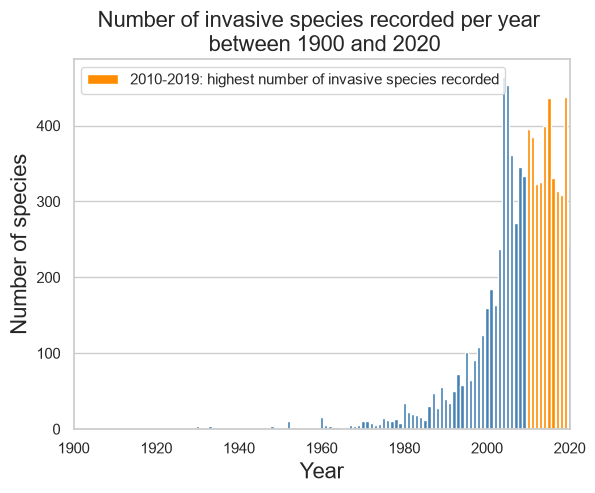

In [18]:
colors = ["darkorange" if 2010 <= year <= 2019 else "steelblue"
    for year in q1h1["year"]]

plt.bar(q1h1["year"], q1h1["species recorded"], 
    color=colors,
    alpha=1)
plt.xlabel("Year", fontsize=16)
plt.ylabel("Number of species", fontsize=16)
plt.title("Number of invasive species recorded per year \n between 1900 and 2020", fontsize=16)
plt.grid(axis="x")
plt.xlim(1900, 2020)
plt.gca().set_axisbelow(True)
plt.legend(handles=[Patch(facecolor="darkorange", label="2010-2019: highest number of invasive species recorded")])
plt.show()

The bar plot shows an increase in the number of invasive species recorded since the 1980s, with a more rapid increase since the 1990s. The decade with the highest number of invasive species recorded is 2010-2019 and is highlited in orange in the bar plot.

#### 4.2 Which region and countries are the most affected by invasive species?

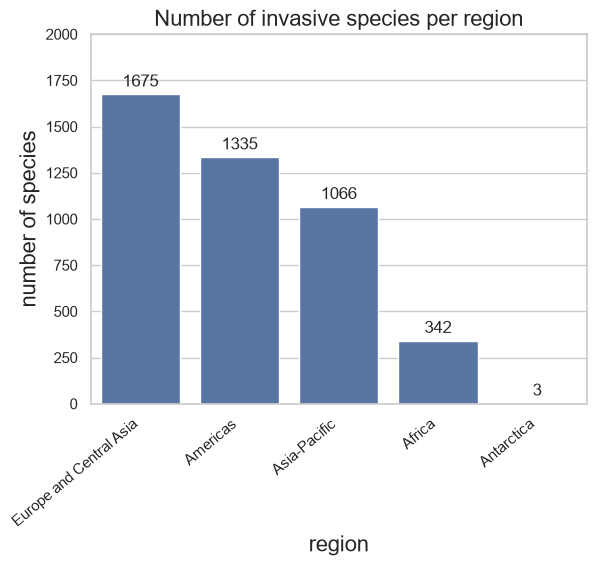

In [33]:

plt_q2h1 = sns.barplot(q2h1, x="region", y="species recorded")
plt_q2h1.set_ylim(0, 2000)
plt_q2h1.set_title("Number of invasive species per region", fontsize=16)
plt_q2h1.set_ylabel("number of species", fontsize=16)
plt_q2h1.set_xlabel("region", fontsize=16)
labels = [label.get_text().replace("_", " ") for label in plt_q2h1.get_xticklabels()]
plt_q2h1.set_xticks(range(len(labels)),labels=labels,rotation=40,ha="right")

for container in plt_q2h1.containers:
    plt_q2h1.bar_label(container, fmt="%.0f", padding=3)

plt.show()


The number of invasive species is the highest in Europe and Central Asia, closely followed by the Americas. The Asia-Pacific region is in third place. Africa is in fourth place with 342 invasive species, and Antartica has the lowest number of invasive species with only three species recorded.

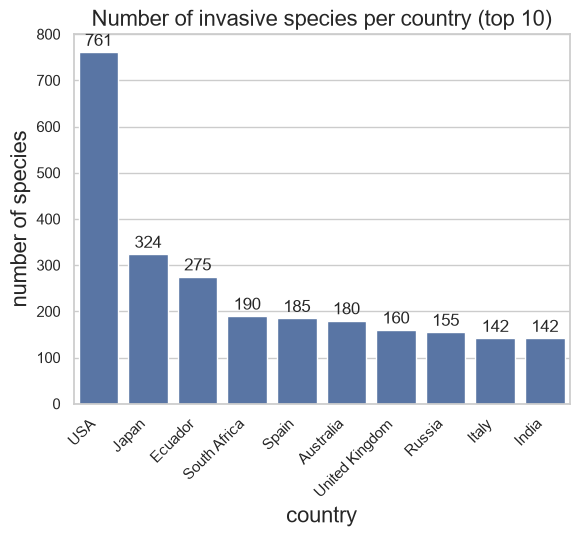

In [20]:
top_10 = q2h2_1.head(10)
plt_q2h2 = sns.barplot(top_10, x="country", y="species recorded")
plt_q2h2.set_ylim(0,  800)
plt_q2h2.set_title("Number of invasive species per country (top 10)",fontsize=16)
plt_q2h2.set_ylabel("number of species", fontsize=16)
plt_q2h2.set_xlabel("country", fontsize=16)
plt.xticks(rotation=45, ha="right")

for container in plt_q2h2.containers:
    plt_q2h2.bar_label(container, fmt="%.0f", padding=2)

plt.show()


According to the bar plot, the USA has the highest number of invasive species, with 761 recorded species. Japan is the country with the second highest number of invasive species, followed by Ecuador, South Africa, Spain, Australia, the United Kingdom, Russia, Italy and India.

#### 4.3 Which invasive species have the greater impact?

##### 4.3.1 Comparing the Animalia and Plantea kingdom

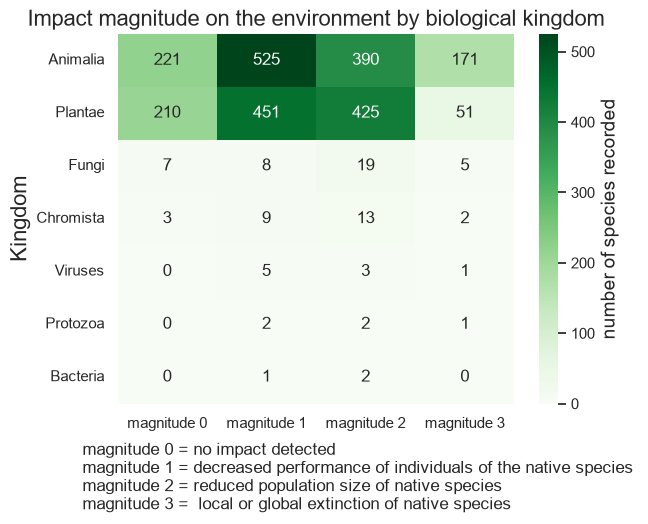

In [21]:
index_q3h1 = q3h1.set_index("kingdom")[["magnitude 0", "magnitude 1", "magnitude 2", "magnitude 3"]]
ax=sns.heatmap(
    index_q3h1,
    annot=True,
    fmt="d",
    cmap="Greens"
)
cbar = ax.collections[0].colorbar
cbar.set_label("number of species recorded", fontsize=14)
plt.xlabel("", fontsize=16)
plt.ylabel("Kingdom",fontsize=16)
plt.title("Impact magnitude on the environment by biological kingdom",fontsize=16)
plt.figtext(0.07, -0.11,
    "magnitude 0 = no impact detected \n" \
    "magnitude 1 = decreased performance of individuals of the native species \n" \
    "magnitude 2 = reduced population size of native species  \n" \
    "magnitude 3 =  local or global extinction of native species",
    ha="left",
    fontsize=12)
plt.show()

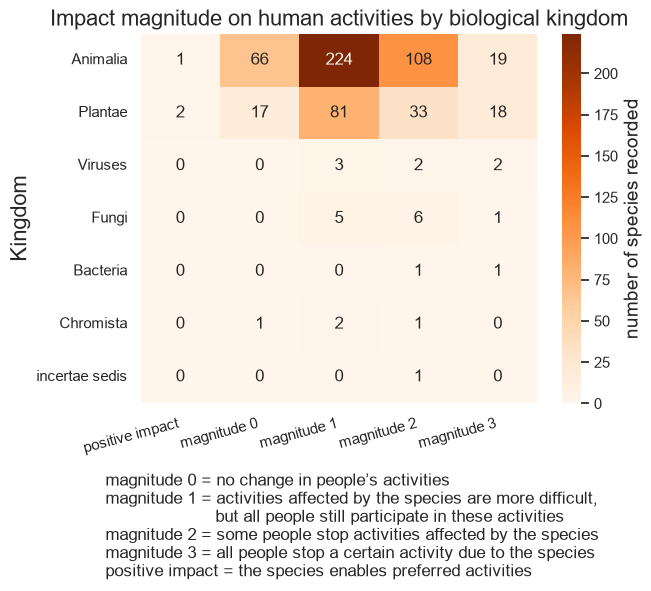

In [ ]:
index_q3h2 = q3h2.set_index("kingdom")[["positive impact","magnitude 0", "magnitude 1", "magnitude 2", "magnitude 3"]]
ax=sns.heatmap(
    index_q3h2,
    annot=True,
    fmt="d",
    cmap="Oranges")

cbar = ax.collections[0].colorbar
cbar.set_label("number of species recorded", fontsize=14)
plt.xlabel("")
plt.ylabel("Kingdom", fontsize=16)
plt.title("Impact magnitude on human activities by biological kingdom", fontsize=16)
plt.xticks(rotation=15, ha="right")
plt.figtext(0.07, -0.25,
    "magnitude 0 = no change in people’s activities \n" \
    "magnitude 1 = activities affected by the species are more difficult, \n" 
    "                      but all people still participate in these activities \n" \
    "magnitude 2 = some people stop activities affected by the species\n" \
    "magnitude 3 = all people stop a certain activity due to the species \n" \
    "positive impact = the species enables preferred activities",
    ha="left",
    fontsize=12)
plt.show()

The Animalia kingdom has the greatest impact on both the environment and human activities, with the highest number of recorded impacts as well as the highest number of magnitude 3 impacts. It is interesting to see that the environment is more affected than human activities, with a higher number of recorded impacts.

##### 4.3.2 Comparing the most impactful taxa in the Plantea and Animalia kingdom.

In [22]:
# Top three taxa with the greatest impact on nature from the Animalia kingdom in the five most affected countries
top3_q3h3_1 = (q3h3_1
    .sort_values(["country", "magnitude 3"], ascending=[True, False])
    .groupby("country")
    .head(3))
top3_q3h3_1

,country,family,magnitude 3
0,Ecuador,Formicidae,8
1,Ecuador,Muridae,2
2,Ecuador,Bovidae,2
9,Japan,Formicidae,2
10,Japan,Suidae,1
11,Japan,Serpulidae,1
19,South Africa,Salmonidae,2
20,South Africa,Mytilidae,2
21,South Africa,Centrarchidae,2
26,Spain,Formicidae,2


In [ ]:
# Top three taxa with the greatest impact on nature from the Plantae kingdom in the five most affected countries
top3_q3h4_1 = (q3h4_1
    .sort_values(["country", "magnitude 3"], ascending=[True, False])
    .groupby("country")
    .head(3))
print(top3_q3h4_1)

         country         family  magnitude 3
0        Ecuador     Formicidae            8
1        Ecuador        Muridae            2
2        Ecuador        Bovidae            2
9          Japan     Formicidae            2
10         Japan         Suidae            1
11         Japan     Serpulidae            1
19  South Africa     Salmonidae            2
20  South Africa      Mytilidae            2
21  South Africa  Centrarchidae            2
26         Spain     Formicidae            2
27         Spain     Colubridae            2
28         Spain        Muridae            1
32           USA     Formicidae           10
33           USA     Spiraxidae            2
34           USA   Scorpaenidae            2


In [23]:
# Top three taxa with the greatest impact on human activities from the Animalia kingdom in the five most affected countries
top3_q3h3_1 = (q3h3_2
    .sort_values(["country", "magnitude 3"], ascending=[True, False])
    .groupby("country")
    .head(3))
print(top3_q3h3_1)

        country       family  magnitude 3
0  South Africa     Corvidae            1
1           USA   Formicidae            1
2           USA  Buprestidae            1


In [24]:
# Top three taxa with the greatest impact on human activities from the Plantae kingdom in the five most affected countries
top3_q3h3_1 = (q3h4_2
    .sort_values(["country", "magnitude 3"], ascending=[True, False])
    .groupby("country")
    .head(3))
print(top3_q3h3_1)

        country        family  magnitude 3
0  South Africa  Salviniaceae            1


These four tables show that the environment is more affected by magnitude 3 impacts than human activities. It is interesting to see that the Formicidae family (ants) has a great impact in four of the most affected countries.

##### 4.3.3 The ten most impactful species

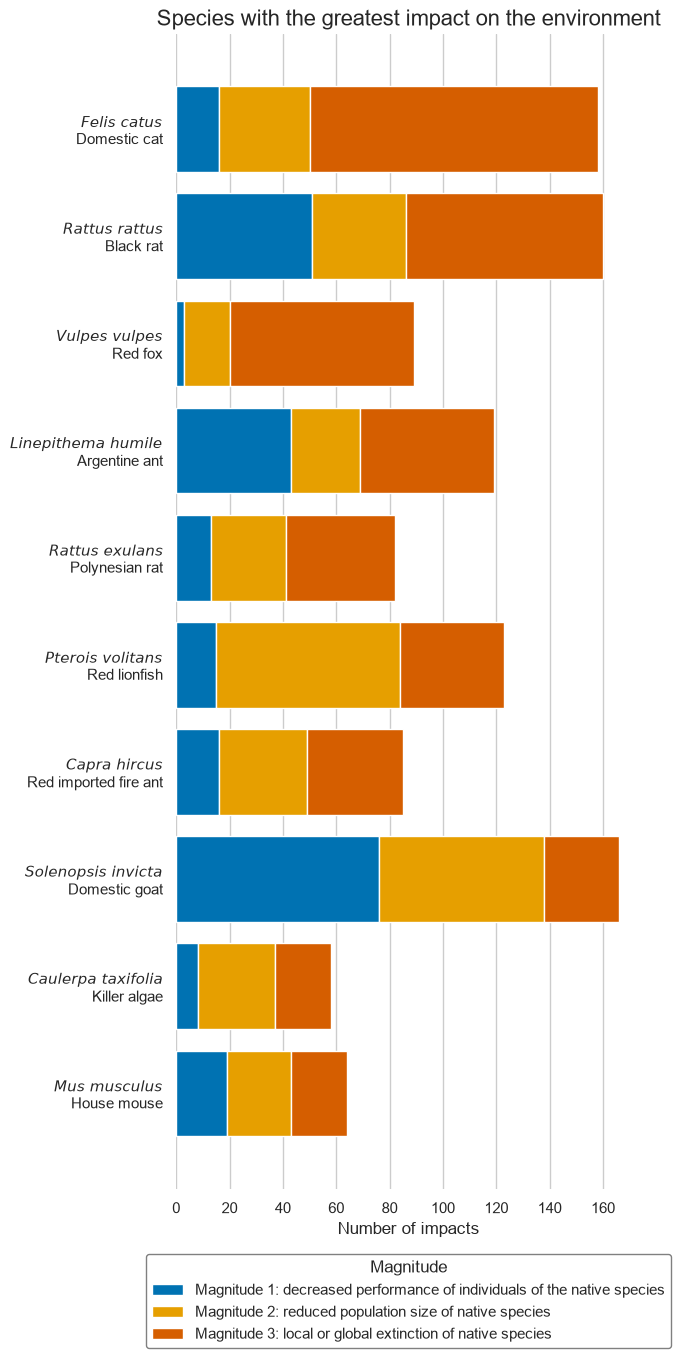

In [30]:
latin_names_q3h5_1 = ["Felis catus","Rattus rattus","Vulpes vulpes","Linepithema humile",
                      "Rattus exulans","Pterois volitans","Capra hircus",
                      "Solenopsis invicta","Caulerpa taxifolia", "Mus musculus"]
common_names_q3h5_1 = ["Domestic cat","Black rat","Red fox","Argentine ant","Polynesian rat",
                       "Red lionfish","Red imported fire ant","Domestic goat","Killer algae","House mouse"]

labels_q3h5_1 = [
    rf"$\it{{{latin.replace(' ', r'\ ')}}}$" + f"\n{name}"
    for latin, name in zip(latin_names_q3h5_1, common_names_q3h5_1)]

sns.set_theme(style="whitegrid")

# Initialize the matplotlib figure
f, ax_q3h5_1 = plt.subplots(figsize=(6, 15))

ax_q3h5_1.barh(
    q3h5_1["species"],
    q3h5_1["magnitude 1"],
    label = "Magnitude 1: decreased performance of individuals of the native species",
    color = "#0072B2")
ax_q3h5_1.barh(
    q3h5_1["species"],
    q3h5_1["magnitude 2"],
    left=q3h5_1["magnitude 1"],
    label = "Magnitude 2: reduced population size of native species",
    color = "#E69F00")
ax_q3h5_1.barh(
    q3h5_1["species"],
    q3h5_1["magnitude 3"],
    left=q3h5_1["magnitude 1"] + q3h5_1["magnitude 2"],
    label = "Magnitude 3: local or global extinction of native species",
    color = "#D55E00")

ax_q3h5_1.set_xlabel("Number of impacts")
ax_q3h5_1.set_ylabel("")
ax_q3h5_1.set_yticks(range(len(labels_q3h5_1)), labels=labels_q3h5_1)
ax_q3h5_1.set_title("Species with the greatest impact on the environment", fontsize=16)

ax_q3h5_1.legend(
    title="Magnitude",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=1,
    frameon=True,
    fancybox=True,
    framealpha=1,
    edgecolor="grey",
    facecolor="white")

ax_q3h5_1.invert_yaxis()
ax_q3h5_1.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)

plt.show()


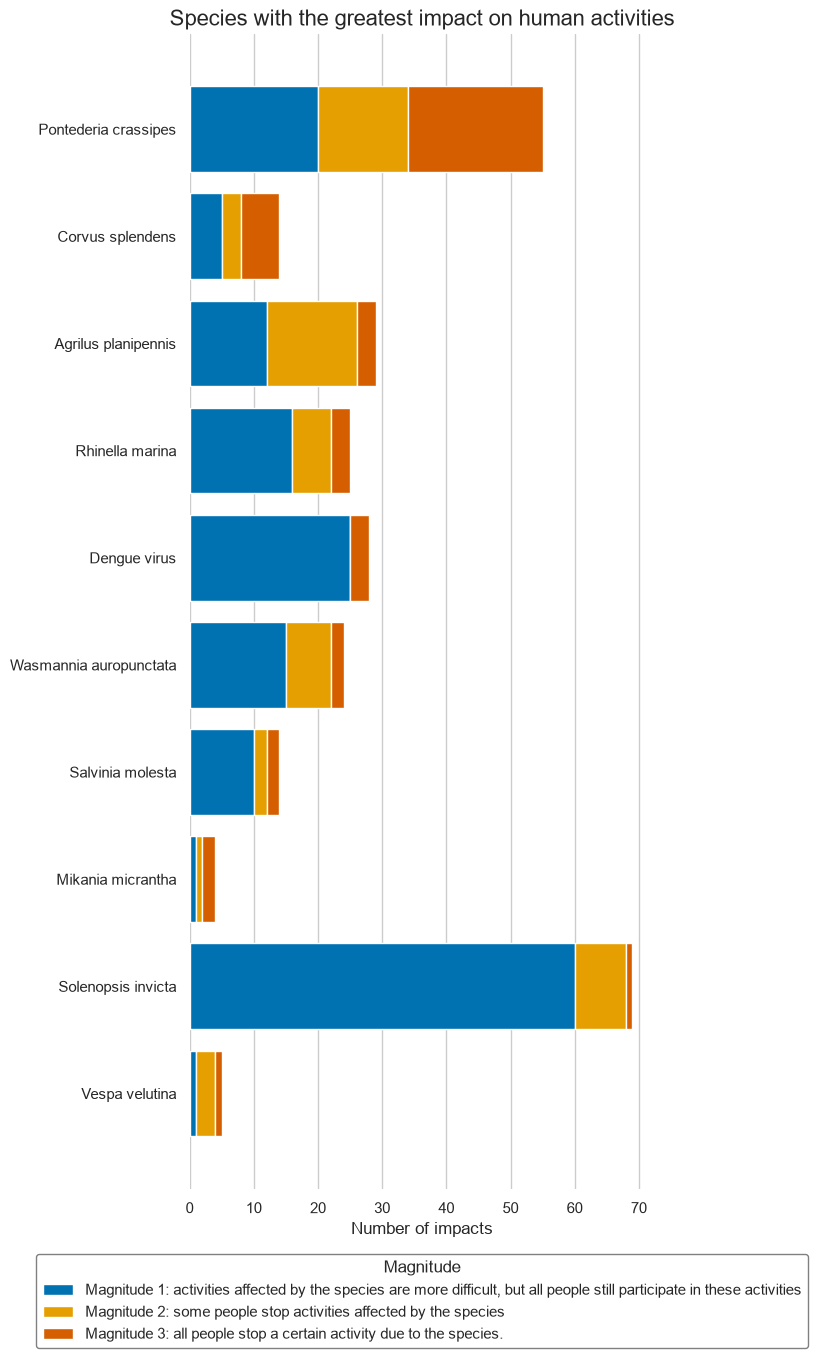

In [32]:
latin_names_q3h5_2 = ["Pontederia crassipes","Corvus splendens","Agrilus planipennis",
                      "Rhinella marina", "Orthoflavivirus denguei","Wasmannia auropunctata",
                      "Salvinia molesta","Mikania micrantha","Solenopsis invicta","Vespa velutina"]
common_names_q3h5_2 = ["Water hyacinth","House crow","Emerald ash borer","Cane toad", "Dengue virus",
                       "Little fire ant","Giant salvinia","Mile-a-minute weed","Red imported fire ant","Yellow-legged hornet"]

labels_q3h5_2 = [
    rf"$\it{{{latin.replace(' ', r'\ ')}}}$" + f"\n{name}"
    for latin, name in zip(latin_names_q3h5_2, common_names_q3h5_2)]

sns.set_theme(style="whitegrid")

f, ax_q3h5_2 = plt.subplots(figsize=(6, 15))

ax_q3h5_2.barh(
    q3h5_2["species"],
    q3h5_2["magnitude 1"],
    label = "Magnitude 1: activities affected by the species are more difficult, but all people still participate in these activities",
    color = "#0072B2")
ax_q3h5_2.barh(
    q3h5_2["species"],
    q3h5_2["magnitude 2"],
    left=q3h5_2["magnitude 1"],
    label = "Magnitude 2: some people stop activities affected by the species",
    color = "#E69F00")
ax_q3h5_2.barh(
    q3h5_2["species"],
    q3h5_2["magnitude 3"],
    left=q3h5_2["magnitude 1"] + q3h5_2["magnitude 2"],
    label = "Magnitude 3: all people stop a certain activity due to the species.",
    color = "#D55E00")

ax_q3h5_2.set_xlabel("Number of impacts")
ax_q3h5_2.set_ylabel("")
ax_q3h5_1.set_yticks(range(len(labels_q3h5_1)), labels=labels_q3h5_1)
ax_q3h5_2.set_title("Species with the greatest impact on human activities", fontsize=16)

ax_q3h5_2.legend(
    title="Magnitude",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=1,
    frameon=True,
    fancybox=True,
    framealpha=1,
    edgecolor="grey",
    facecolor="white")
ax_q3h5_2.invert_yaxis()
ax_q3h5_2.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)

plt.show()


The horizontal bar plots display the species with the highest number of magnitude 1, 2 and 3 impacts. It is important to note that the number of impacts and the number of magnitude 3 impacts for the environment is higher than for human activities. Interestingly, the proportion of magnitude 1 impacts is higher when looking at the impact on human activities. Looking at both bar plots it is visisble that ant species are present in the ten species with the highest impact. This correlates with the eralier findings. 

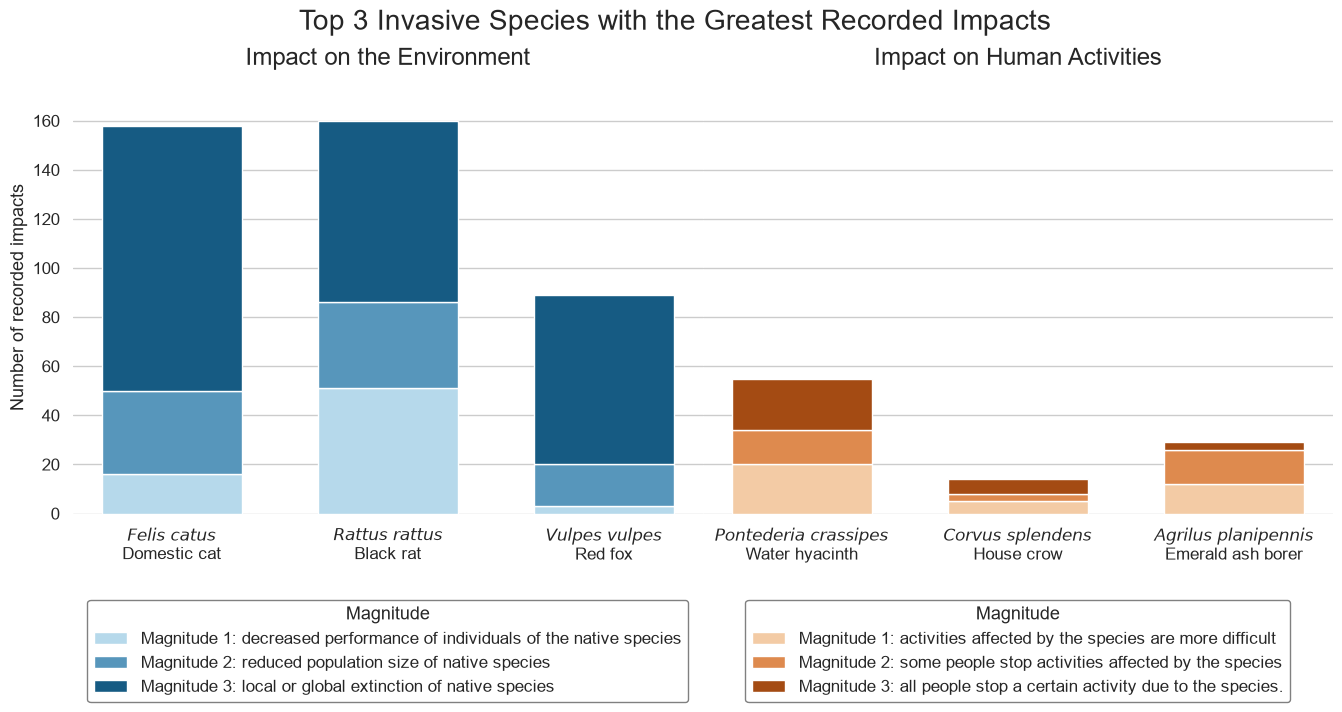

In [55]:

# Selecting the top 3 species from each SQL ranking
environment = q3h5_1.head(3).copy()
human_activities = q3h5_2.head(3).copy()

common_names = {
    "Felis catus": "Domestic cat",
    "Rattus rattus": "Black rat",
    "Vulpes vulpes": "Red fox",
    "Pontederia crassipes": "Water hyacinth",
    "Corvus splendens": "House crow",
    "Agrilus planipennis": "Emerald ash borer"}

# Colour gradients from light (magnitude 1) to dark (magnitude 3)
environment_colors = ["#B6D9EB", "#5796BB", "#165B83"]
human_colors = ["#F3CBA5", "#DE8A4E", "#A44B13"]

# Legend descriptions
environment_labels = ["Magnitude 1: decreased performance of individuals of the native species",
                      "Magnitude 2: reduced population size of native species",
                      "Magnitude 3: local or global extinction of native species"]

human_labels = ["Magnitude 1: activities affected by the species are more difficult",
                "Magnitude 2: some people stop activities affected by the species",
                "Magnitude 3: all people stop a certain activity due to the species."]

sns.set_theme(style="whitegrid", font_scale=1.2)

# Shared y-axis and aligned x-axis baseline
fig, axes = plt.subplots(1, 2,figsize=(14, 9),sharey=True,sharex=False)

def plot_impacts(ax, data, colors, legend_labels, title):
    x = np.arange(len(data))
    bottom = np.zeros(len(data))

    for magnitude, color, legend_label in zip(
        ["magnitude 1", "magnitude 2", "magnitude 3"],
        colors,
        legend_labels):
        values = data[magnitude].to_numpy()

        ax.bar(
            x,
            values,
            bottom=bottom,
            color=color,
            label=legend_label,
            width=0.65)
        bottom += values

    labels = [
        rf"$\it{{{species.replace(' ', chr(92) + ' ')}}}$"
        + f"\n{common_names[species]}"
        for species in data["species"]]

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=12)
    ax.tick_params(axis="y", labelsize=12)
    ax.set_title(title, fontsize=17, pad=12)

    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

    ax.legend(
        title="Magnitude",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        fontsize=12,
        title_fontsize=13,
        frameon=True,
        fancybox=True,
        framealpha=1,
        edgecolor="grey",
        facecolor="white",
        ncol=1)

    sns.despine(ax=ax, left=True, bottom=True)


plot_impacts(axes[0], environment, environment_colors, environment_labels, "Impact on the Environment")

plot_impacts(axes[1], human_activities, human_colors, human_labels, "Impact on Human Activities")

# Setting the same y-axis range
max_environment = environment[["magnitude 1", "magnitude 2", "magnitude 3"]].sum(axis=1).max()

max_human = human_activities[["magnitude 1", "magnitude 2", "magnitude 3"]].sum(axis=1).max()

y_max = max(max_environment, max_human) * 1.1

axes[0].set_ylim(0, y_max)
axes[0].set_ylabel("Number of recorded impacts", fontsize=13)
axes[1].set_ylabel("")

fig.suptitle("Top 3 Invasive Species with the Greatest Recorded Impacts",fontsize=20, y=0.94)

fig.subplots_adjust(left=0.07, right=0.97, top=0.86, bottom=0.38, wspace=0)

plt.show()


The graph compares the three invasive species with the greatest recorded impacts on the environment and on human activities, respectively. Overall, the number of recorded impacts is considerably higher for the environment than for human activities.

---
## 5. Conclusions

1. When did invasive species introductions peak, and was there a period of rapid increase?

The number of alien invasive species has been increasing since 1600, which is the year of first record in the dataset. The rate of the increase has become more pronounced since 1990s. The decade with the most recorded invasive alien species has been 2010-2019. A peak is not yet visible, as the number of alien species still seems to be increasing.
The hypothesis were partially correct.

2. Which region and countries are the most affected by invasive species?

The region most affected by invasive alien species is Europe and Central Asia. Therefore, the hypothesis was not corect. Africa is the second-least affected region, with 342 invasive species recorded.

Nevertheless, South Africa ranks fourth among the countries with the highest number of invasive species. The United States has the highest number, followed by Japan, Ecuador, South Africa, and Spain. Therefore, the hypothesis was partially correct.

3. Which invasive species have the greater impact?

First, taking a look at the impact of invasive species on the environment and human activities, grouped by kingdom, the results show that species from the Animalia kingdom have the greatest impact on both the environment and human activities. The hypothesis was therefore only partially correct.

In the five most affected countries, the taxonomical families from the Animalia kingdom affecting the environment the most are, for Ecuador, Formicidae, Muridae, and Bovidae; for Japan, Formicidae, Suidae, and Serpulidae; for South Africa, Salmonidae, Mytilidae, and Centrarchidae; for Spain, Formicidae, Colubridae, and Muridae; and for the USA, Formicidae, Spiraxidae, and Scorpaenidae.

Taxonomical families from the Animalia kingdom affecting human activities the most were only reported in the USA and South Africa. For South Africa, it is the Corvidae family, while for the USA, it is one species from the Formicidae family and one from the Buprestidae family.

Now, taking a look at the most impactful families from the Plantae kingdom in the five most affected countries, the most impactful families for Ecuador are Solanaceae and Meliaceae; for Japan, Pontederiaceae, Moraceae, and Hydrocharitaceae; for South Africa, Salviniaceae, Pontederiaceae, and Pinaceae; for Spain, Rhodomelaceae and Poaceae; and for the USA, Poaceae, Hydrocharitaceae, and Typhaceae.

Only the USA and South Africa reported families from the Plantae kingdom impacting human activities. For South Africa, it is one species from the Corvidae family, while for the USA, it is one species from the Formicidae family and one from the Buprestidae family.
The results show that the hypotheses cannot be supported.

Lastly, the impact magnitudes one to three were counted and compared across all species. The ten species with the highest impact on the environment are: *Felis catus*, *Rattus rattus*, *Vulpes vulpes*, *Linepithema humile*, *Rattus exulans*, *Pterois volitans*, *Mus musculus*, *Solenopsis invicta*, *Capra hircus*, and *Caulerpa taxifolia*.

The ten species with the highest impact on human activities are: *Pontederia crassipes*, *Corvus splendens*, *Agrilus planipennis*, *Rhinella marina*, *Orthoflavivirus denguei*, *Wasmannia auropunctata*, *Salvinia molesta*, *Mikania micrantha*, *Solenopsis invicta*, and *Vespa velutina*.

It is interesting to note that ant species have a high impact on both human activities and the environment.


---
## 6. Limitations and next steps

The analysis gives us an overview of the evolution of the number of invasive species but does not show how the introduction of these species took place. Knowledge about the introduction of invasive species is key to preventing them from spreading.

Furthermore, it has to be acknowledged that the analysis of the number of invasive species per country is not complete. As some locations contain lists of countries, not all countries could be taken into consideration during the analysis. In the same way, some locations are islands that are part of countries and therefore might result in a country being counted twice for the same species. In hindsight, this dataset might have been too complex for such a short project. The data cleaning should have been more thorough.

With a cleaner dataset, it would be interesting to compare islands to determine whether they are more at risk from invasive alien species and whether they are more affected by certain species or groups of species.

An additional interesting analysis would have been to examine the countries most affected by the most invasive species. Creating a map with a colour gradient to illustrate how affected a country is by a certain species or family of species could provide interesting insights into the distribution of invasive alien species.